# Godot lifecycles

**The idea:** most "why is this null?" and "why did my value get overwritten?" bugs are ordering bugs. Godot does things in a fixed order; once you know the order, these stop being mysteries.

There are five lifecycles worth knowing. They nest inside each other.

| # | Lifecycle | The question it answers |
|---|---|---|
| 1 | **Birth of an object** | In what order do defaults, `_init`, `@export` values and `_ready` happen? |
| 2 | **Life of a node** | What gets called from creation to deletion? |
| 3 | **Parent and children** | Who goes first? |
| 4 | **A frame** | What happens 60 times a second, and in what order? |
| 5 | **Loading a scene** | How does a `.tscn` become live nodes? |

Then: Node vs Resource (section 6), editor vs game (7), death (8), your own `_Core_Viewport` lifecycle (9), a cheat sheet (10) and an experiment to run in Godot (11).

Companion notebooks in this folder: `data-driven-design-in-godot.ipynb`, `godot-editor-as-a-toolbox.ipynb`.


## 1. Birth of an object

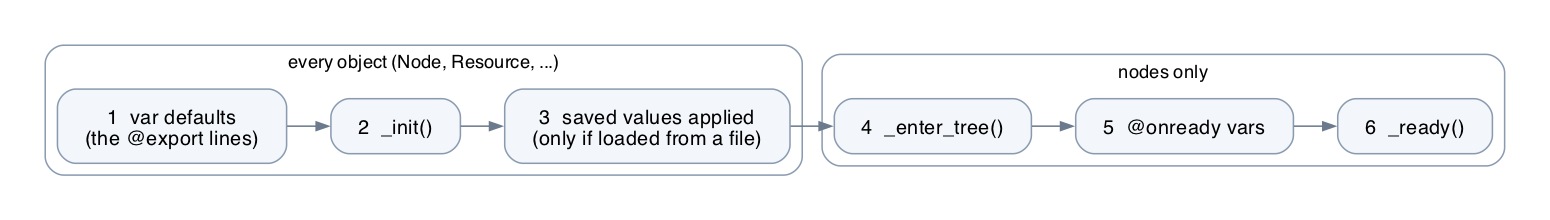

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  nodesep=0.3; ranksep=0.4;
  subgraph cluster_any {
    label="every object (Node, Resource, ...)"; fontname="Helvetica"; fontsize=12; color="#8a9bb0"; style="rounded";
    a [label="1  var defaults\n(the @export lines)"];
    b [label="2  _init()"];
    c [label="3  saved values applied\n(only if loaded from a file)"];
  }
  subgraph cluster_node {
    label="nodes only"; fontname="Helvetica"; fontsize=12; color="#8a9bb0"; style="rounded";
    d [label="4  _enter_tree()"];
    e [label="5  @onready vars"];
    f [label="6  _ready()"];
  }
  a -> b -> c -> d -> e -> f;
}
```

</details>

This order never changes. Each step can overwrite the one before it.

| Step | What happens | Wins over |
|---|---|---|
| 1 | Variables get the default written on their line (`@export var hp := 10`) | Nothing yet |
| 2 | `_init()` runs | Step 1 |
| 3 | Values saved in the scene or `.tres` are applied (what you set in the Inspector) | Steps 1 and 2 |
| 4 | `_enter_tree()`: the node joins the tree | |
| 5 | `@onready` variables are filled in | |
| 6 | `_ready()` runs | |

**What can I use where?**

| | `_init` | `_enter_tree` | `_ready` |
|---|---|---|---|
| Defaults from the `var` lines | yes | yes | yes |
| Values set in the Inspector | **no** | yes | yes |
| Parent, `get_tree()` | **no** | yes | yes |
| My children | **no** | they exist, but are not ready | yes, and they are ready |
| `@onready` variables | **no** | **no** | yes |

**Two details that cause most surprises:**

- Godot only saves a field that **differs from its default**. An untouched field has nothing to apply in step 3, so it keeps whatever steps 1 and 2 left.
- Step 3 goes through the variable's **setter**, and the node is not in the tree yet. A setter that touches children will fail there. That is why `_rpgm_mover.gd` checks `is_node_ready()` first.

**Same class, two ways of being born** (a lambda, as an example):

| Step | Loaded from a scene (data dev) | Made with `.new(...)` (code dev) |
|---|---|---|
| 1 | The `@export var` defaults are set | The `@export var` defaults are set |
| 2 | `_init()` runs with no arguments, so it changes nothing | `_init(["Hi"])` runs and overrides with what you passed |
| 3 | The values saved from the Inspector are applied on top | Nothing; there is no saved data |
| **Final value** | **What the Inspector shows** | **What the code passed** |


### Who calls `_init`, and with what?

"Defined in the editor" does not mean "created by the editor". The editor only writes a recipe into the scene file. The object is created later, in the running game.

| | 1. You edit in the Inspector | 2. You press Play, the scene loads | 3. Game code calls `.new(["Hi"])` |
|---|---|---|---|
| Which program | The editor | The running game | The running game |
| Who creates the object | Nobody; only text is saved to the `.tscn` | **Godot's scene loader** (engine code, not yours) | Your code |
| Is `_init` called | No (no `@tool`, so the script does not run) | **Yes, always with zero arguments** | Yes, with your arguments |
| How values get in | Saved to the file | Set directly on each variable, by name, after `_init` | Whatever `_init` does with the arguments |

**Two separate channels into an object.** The loader does not know that an `_init` parameter and an `@export` variable are related, so it never fills one from the other.

| Channel | Used by | How the value gets in |
|---|---|---|
| `_init` parameters | Code only | Passed as arguments to `.new(...)` |
| `@export` variables | The scene loader and the Inspector | Set on the variable directly |

**The rule:** the `@export` default is the starting point. `_init` arguments override it for code callers. Inspector values override it for scene content. The two overrides never meet, because a scene load always calls `_init()` empty.

The pattern that follows from this (from `_rpgm_lambda_show_messages.gd`):

```gdscript
@export var messages : Array[String] = ["Empty array."]   # the default lives here

func _init(messages_ = null):                             # null means "not passed"
	if messages_ != null: messages.assign(messages_)
```

| How the lambda is created | `_init` receives | Then | Final `messages` |
|---|---|---|---|
| From a scene, field untouched in the Inspector | `null` | Nothing saved to apply | The export default, `["Empty array."]` |
| From a scene, field edited in the Inspector | `null` | Saved value applied | What the Inspector shows |
| From code, `.new()` | `null` | Nothing | The export default |
| From code, `.new(["Hi"])` | `["Hi"]` | Nothing | `["Hi"]` |

| Rule for `_init` | Why |
|---|---|
| Every parameter needs a default | The loader calls `_init()` with nothing; a required parameter makes the object fail to load |
| Keep the real defaults on the `@export` lines | The editor never runs `_init`, so the Inspector can only show what is on those lines |
| Use `.assign()` to put an untyped array into a typed one | `=` refuses a plain `Array` going into `Array[String]` |


### Feel it: who wins?

A toy of steps 1 to 3 for one field, `scale`, default `5`. Same lambda, three ways of coming to life.


In [1]:
def birth(saved=None, passed=None):
	log = []
	scale = 5;                         log.append("1 default        -> 5")
	if passed is not None:
		scale = passed;                log.append(f"2 _init({passed})       -> {scale}")
	else:
		log.append("2 _init()        -> unchanged")
	if saved is not None:
		scale = saved;                 log.append(f"3 saved value    -> {scale}")
	else:
		log.append("3 nothing saved  -> unchanged")
	return scale, log

cases = {
	"data dev, field untouched in Inspector": dict(),
	"data dev, set 8 in Inspector":           dict(saved=8),
	"code dev, .new(2)":                      dict(passed=2),
}
for title, kwargs in cases.items():
	final, log = birth(**kwargs)
	print(title)
	for line in log: print("   ", line)
	print(f"    FINAL scale = {final}\n")

data dev, field untouched in Inspector
    1 default        -> 5
    2 _init()        -> unchanged
    3 nothing saved  -> unchanged
    FINAL scale = 5

data dev, set 8 in Inspector
    1 default        -> 5
    2 _init()        -> unchanged
    3 saved value    -> 8
    FINAL scale = 8

code dev, .new(2)
    1 default        -> 5
    2 _init(2)       -> 2
    3 nothing saved  -> unchanged
    FINAL scale = 2



In [2]:
# ----- student scratchpad ----- 

## 2. Life of a node

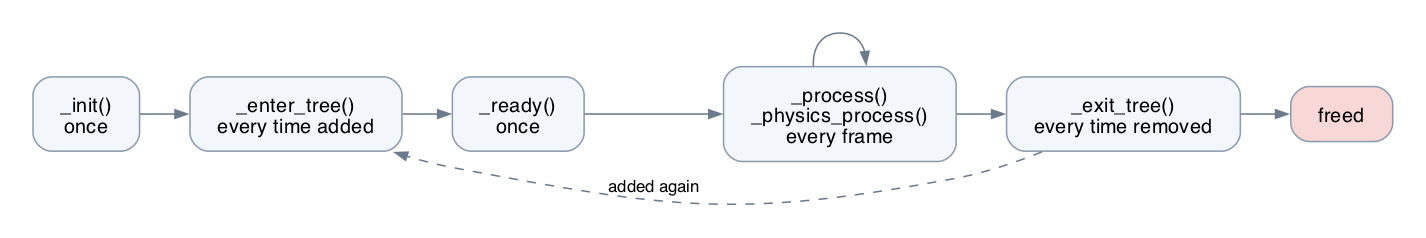

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  nodesep=0.3; ranksep=0.45;
  i [label="_init()\nonce"];
  e [label="_enter_tree()\nevery time added"];
  r [label="_ready()\nonce"];
  p [label="_process()\n_physics_process()\nevery frame"];
  x [label="_exit_tree()\nevery time removed"];
  f [label="freed", fillcolor="#f8d7d7"];
  i -> e -> r -> p -> x -> f;
  p -> p;
  x -> e [label="added again", style=dashed, constraint=false];
}
```

</details>

| Callback | How often | Use it for |
|---|---|---|
| `_init()` | Once, at creation | Setting up plain variables. No tree, no children, no Inspector values |
| `_enter_tree()` | **Every time** the node is added to the tree | Things that depend on *where* the node is (its parent) |
| `_ready()` | **Once**, the first time it enters with all children ready | Normal setup: grab children, connect signals |
| `_process(delta)` | Every drawn frame | Visuals, UI, anything that should be smooth |
| `_physics_process(delta)` | Fixed rate (60 per second by default) | Movement, collisions, anything that must be consistent |
| `_exit_tree()` | **Every time** it is removed | Undo what `_enter_tree` did, stop audio |

The trap in this picture: remove a node and add it back, and `_enter_tree` runs again but `_ready` does **not**. Call `request_ready()` before re-adding if you need it to.


## 3. Parent and children: who goes first?

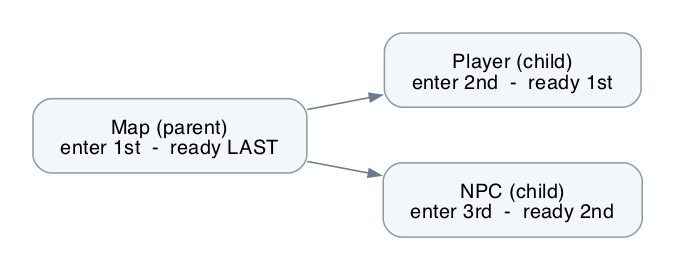

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  map    [label="Map (parent)\nenter 1st  -  ready LAST"];
  player [label="Player (child)\nenter 2nd  -  ready 1st"];
  npc    [label="NPC (child)\nenter 3rd  -  ready 2nd"];
  map -> player;
  map -> npc;
}
```

</details>

| Callback | Order | Why it makes sense |
|---|---|---|
| `_enter_tree` | **Parent first**, then children | A child needs its parent to already be in the tree |
| `_ready` | **Children first**, parent last | A parent's `_ready` can rely on all its children being set up |
| `_process` | Parent first, then children | Tree order, top to bottom (`process_priority` can change it) |
| `_exit_tree` | **Children first**, parent last | The reverse of entering |

So in `_ready` you can safely look **down** (children are done) but not **up** or **sideways**: your parent and your later siblings are not ready yet.


### Feel it: the order, printed

Change the tree and re-run.

In [3]:
class Node:
	def __init__(self, name, *children): self.name, self.children = name, children

def enter(node, log):                       # parent first
	log.append(f"_enter_tree  {node.name}")
	for child in node.children: enter(child, log)

def ready(node, log):                       # children first
	for child in node.children: ready(child, log)
	log.append(f"_ready       {node.name}")

def leave(node, log):                       # children first, last child first
	for child in reversed(node.children): leave(child, log)
	log.append(f"_exit_tree   {node.name}")

tree = Node("Map",
	Node("Player", Node("Sprite")),
	Node("NPC"),
)

log = []
enter(tree, log); ready(tree, log)
log.append("... the game runs ...")
leave(tree, log)
print("\n".join(log))

_enter_tree  Map
_enter_tree  Player
_enter_tree  Sprite
_enter_tree  NPC
_ready       Sprite
_ready       Player
_ready       NPC
_ready       Map
... the game runs ...
_exit_tree   NPC
_exit_tree   Sprite
_exit_tree   Player
_exit_tree   Map


In [4]:
# ----- student scratchpad ----- 

## 4. A frame

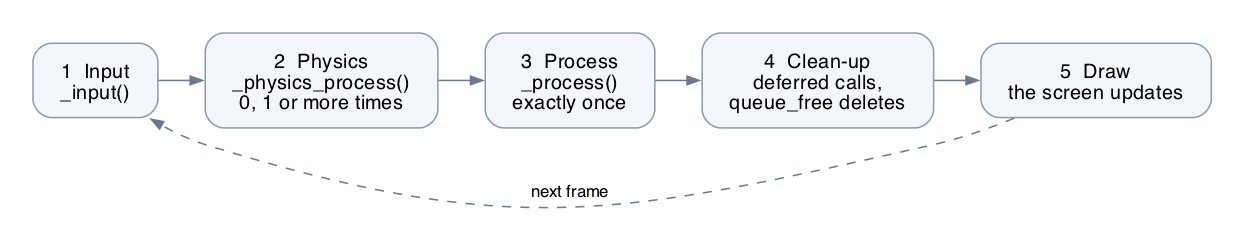

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  nodesep=0.3; ranksep=0.4;
  i [label="1  Input\n_input()"];
  ph [label="2  Physics\n_physics_process()\n0, 1 or more times"];
  pr [label="3  Process\n_process()\nexactly once"];
  d [label="4  Clean-up\ndeferred calls,\nqueue_free deletes"];
  dr [label="5  Draw\nthe screen updates"];
  i -> ph -> pr -> d -> dr;
  dr -> i [label="next frame", style=dashed, constraint=false];
}
```

</details>

| | `_process(delta)` | `_physics_process(delta)` |
|---|---|---|
| Runs | Once per drawn frame | At a fixed rate, 60 per second by default |
| `delta` | Varies with frame rate | Constant |
| Per frame | Exactly 1 | 0, 1 or several, to keep up with the clock |
| Put here | Visuals, UI, camera smoothing | Movement, collisions, game rules |

**Things that do not wait for "their turn":**

| Thing | When it actually runs |
|---|---|
| A signal you `emit` | **Immediately**, inside the emit call, before the next line |
| `await some_signal` | Resumes at the moment that signal is emitted |
| `call_deferred(...)` | Step 4 of the same frame, after the current work is finished |
| `queue_free()` | Marks the node; it is deleted in step 4 |
| `await get_tree().process_frame` | Resumes at the start of step 3 of the next frame |

**Input order** inside step 1: `_input()` first, then UI controls get a chance to use the event, then `_unhandled_input()` for whatever is left. Put gameplay keys in `_unhandled_input` so buttons and text boxes win.


### Feel it: physics ticks vs frames

Physics always ticks 60 times a second. The screen may not. Watch how many physics ticks fit in each frame.

In [5]:
PHYSICS_TICKS_PER_SECOND = 60

def simulate(fps, frames=6):
	print(f"screen at {fps} fps")
	owed = 0.0                                   # physics time we still owe
	for frame in range(1, frames + 1):
		owed += 1 / fps
		ticks = 0
		while owed >= 1 / PHYSICS_TICKS_PER_SECOND - 1e-9:
			owed -= 1 / PHYSICS_TICKS_PER_SECOND
			ticks += 1
		print(f"   frame {frame}:  _physics_process x{ticks}   _process x1")
	print()

simulate(60)
simulate(30)     # slow machine, or a heavy web build
simulate(144)    # fast monitor

screen at 60 fps
   frame 1:  _physics_process x1   _process x1
   frame 2:  _physics_process x1   _process x1
   frame 3:  _physics_process x1   _process x1
   frame 4:  _physics_process x1   _process x1
   frame 5:  _physics_process x1   _process x1
   frame 6:  _physics_process x1   _process x1

screen at 30 fps
   frame 1:  _physics_process x2   _process x1
   frame 2:  _physics_process x2   _process x1
   frame 3:  _physics_process x2   _process x1
   frame 4:  _physics_process x2   _process x1
   frame 5:  _physics_process x2   _process x1
   frame 6:  _physics_process x2   _process x1

screen at 144 fps
   frame 1:  _physics_process x0   _process x1
   frame 2:  _physics_process x0   _process x1
   frame 3:  _physics_process x1   _process x1
   frame 4:  _physics_process x0   _process x1
   frame 5:  _physics_process x1   _process x1
   frame 6:  _physics_process x0   _process x1



In [6]:
# ----- student scratchpad ----- 

This is why movement written in `_process` without `delta` runs at different speeds on different machines, and why game rules belong in `_physics_process`.


## 5. Loading a scene

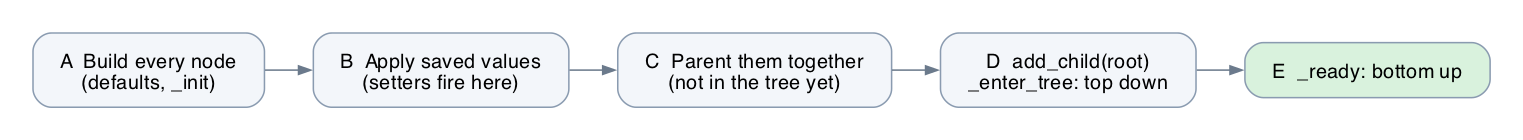

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  nodesep=0.3; ranksep=0.45;
  a [label="A  Build every node\n(defaults, _init)"];
  b [label="B  Apply saved values\n(setters fire here)"];
  c [label="C  Parent them together\n(not in the tree yet)"];
  d [label="D  add_child(root)\n_enter_tree: top down"];
  e [label="E  _ready: bottom up", fillcolor="#d9f2dd"];
  a -> b -> c -> d -> e;
}
```

</details>

`instantiate()` does A, B and C. Nothing is in the tree yet. `add_child()` does D and E.

| Stage | Done by | State of the nodes |
|---|---|---|
| A, B, C | `scene.instantiate()` | Fully built and wired together, Inspector values applied, **not in the tree** |
| D, E | `add_child(root)` | In the tree; `_ready` has run on all of them |

So between the two calls you can still set things on the new scene **before** any `_ready` runs:

```gdscript
var enemy = enemy_scene.instantiate()
enemy.hp = 50            # arrives before enemy._ready()
add_child(enemy)         # _enter_tree and _ready happen here
```

**Same node, two ways of being born:**

| Step | From a scene (`instantiate()`) | Made in code (`.new()`) |
|---|---|---|
| 1 | The `@export var` defaults are set | The `@export var` defaults are set |
| 2 | `_init()` runs with no arguments | `_init(...)` runs with whatever you pass |
| 3 | Inspector values are applied (setters fire) | Nothing; you set fields yourself on the next lines |
| 4 | The scene's children are built and attached | No children unless your code adds them |
| 5 | `add_child()`: `_enter_tree`, then `_ready` | `add_child()`: `_enter_tree`, then `_ready` |
| **Result** | **A complete, configured subtree** | **A bare node holding only what the code gave it** |

**At game start**, autoloads go through all of this first, then the main scene. Static variables are set even earlier, once, when their script is first loaded.


## 6. Node vs Resource vs plain objects

Not everything has the node lifecycle.

| | Node | Resource | RefCounted | Object |
|---|---|---|---|---|
| Example | `_RPGM_Event` | `_RPGM_Lambda`, a texture | A helper class | Rare, low level |
| Birth steps 1 to 3 (defaults, `_init`, saved values) | yes | yes | 1 and 2 only | 1 and 2 only |
| Tree callbacks (`_ready`, `_process`, ...) | yes | **no** | no | no |
| Can be saved in a scene with `@export` values | yes | yes | no | no |
| Dies when | You free it, or its parent is freed | Nobody references it any more | Nobody references it any more | You call `free()` |

**Side by side, both saved in the same scene:**

| Step | Node (`_RPGM_Event`) | Resource (`_RPGM_Lambda`) |
|---|---|---|
| 1 | The `@export var` defaults are set | The `@export var` defaults are set |
| 2 | `_init()` runs | `_init()` runs |
| 3 | Inspector values are applied | Inspector values are applied |
| 4 | `_enter_tree()` | Never; it is not in the tree |
| 5 | `@onready` variables are filled | Not available |
| 6 | `_ready()` | Never |
| While alive | `_process` every frame | Runs only when something calls `run()` |
| Dies | With its parent, or on `queue_free()` | When nothing references it any more |

**What this means for lambdas (Resources):**

| Fact | Consequence |
|---|---|
| No tree | No `_ready`, no `get_node`. Everything it needs must be passed in (`run(rpgm_node)`) |
| Loaded files are shared | `load("x.tres")` twice gives the **same object**. Sub-resources inside a scene are shared between instances of that scene too |
| Shared means shared state | Never store runtime state on a lambda; keep it in local variables inside `run()` |
| Dies when unreferenced | A lambda made with `.new()` and not stored anywhere can disappear |


## 7. Editor vs game

The same script behaves differently depending on where it is.

| | Running game | Editor, no `@tool` | Editor, with `@tool` |
|---|---|---|---|
| Script code runs | yes | **no** | yes |
| `_init`, `_ready`, `_process` | yes | no | yes |
| Inspector shows defaults from | n/a | The `@export var` lines | The `@export var` lines |
| Setters fire when you edit a field | n/a | no | yes |

**Opening the same scene, step by step:**

| Step | Running game | Editor, no `@tool` | Editor, with `@tool` |
|---|---|---|---|
| 1 | Defaults are set | Defaults are read off the `@export var` lines, no code runs | Defaults are set |
| 2 | `_init()` runs | Skipped | `_init()` runs |
| 3 | Saved values are applied, setters fire | Saved values are shown in the Inspector, setters do not fire | Saved values are applied, setters fire |
| 4 | `_enter_tree`, `_ready` | Skipped | `_enter_tree`, `_ready` |
| 5 | `_process` every frame | Skipped | `_process` every frame, while you edit |
| **Result** | **The game** | **A static picture of the data** | **A live preview** |

Two consequences you already met:

- A default set only inside `_init` is **invisible to the Inspector**. Put defaults on the `@export` lines.
- A `@tool` script runs its whole lifecycle inside the editor, so guard game-only code with `Engine.is_editor_hint()`.


## 8. Death

| Action | What happens | When |
|---|---|---|
| `queue_free()` | `_exit_tree`, then deleted, children included | End of the current frame (safe) |
| `free()` | Deleted | Right now (crashes if something is mid-use) |
| `remove_child(n)` | `_exit_tree`, but the node **still exists** | Right now |
| Last reference to a Resource dropped | Deleted | Right then |

| Trap | What you see | Avoid it by |
|---|---|---|
| `remove_child` without freeing | Memory slowly grows (an orphan node) | `queue_free()` it, or keep it on purpose and re-add later |
| Using a node after `queue_free()` | "previously freed" errors | Check `is_instance_valid(node)` |
| A coroutine waiting on a freed node | It never resumes, or errors | Don't free things that are mid-`await`; stop the sequence first |
| Audio after the scene is gone or paused | Sound keeps playing | Stop it in `_exit_tree` or your finish hook |


## 9. Your own lifecycle on top: `_Core_Viewport`

Godot's lifecycle says when a node *exists*. Yours says when a game scene is *active*. From `CLAUDE.md`:

| Layer | Stages | Decided by |
|---|---|---|
| Godot | `_init` > `_enter_tree` > `_ready` > process > `_exit_tree` | The engine |
| `_Core_Viewport` | Start > Activate > Deactivate > Finish (`_on_viewport_start`, `_on_viewport_finish`) | `_Core`, in the transition functions |

How suspension interacts with the frame loop:

| While a scene is suspended | Still happens? |
|---|---|
| `_process`, `_physics_process`, `_input` | **no** (`PROCESS_MODE_DISABLED`) |
| Drawing | **no** (viewport `UPDATE_DISABLED`) |
| Signals connected to its nodes | **yes** |
| Coroutines already waiting on an `await` | **yes**, they resume when their signal fires |
| Audio | **yes**, stop it in `_on_viewport_finish` |

Scenes boot suspended: `_ready` has run, but no frames reach them until `_Core` resumes them.


## 10. Cheat sheet: where do I put it?

| I want to... | Put it in | Because |
|---|---|---|
| Give a field its default | The `@export var` line | The editor reads it there |
| Accept inputs when created from code | `_init(args with defaults)` | Runs at `.new(...)` |
| Use Inspector values | `_ready` (or `run()` for a lambda) | They are not there yet in `_init` |
| Grab child nodes | `@onready var` or `_ready` | Children are ready by then |
| React to a field changing | A setter, guarded by `is_node_ready()` | The setter also fires during loading, before the tree |
| Talk to my parent or siblings | After `_ready`, or `call_deferred` | They are not ready during my `_ready` |
| Move things | `_physics_process` | Same speed on every machine |
| Animate visuals, update UI | `_process` | Once per drawn frame |
| Handle gameplay keys | `_unhandled_input` | UI gets first pick |
| Change the tree while it is busy | `call_deferred` / `queue_free` | Waits for the safe point in the frame |
| Clean up | `_exit_tree` | Runs on every removal |


## 11. See it for real

Attach this to a node in a scratch scene, set `hp` to `99` in the Inspector, and run the scene. I have not run it in your project.

```gdscript
extends Node

@export var hp := 10:
	set(value):
		hp = value
		print("setter       hp=", hp, "  in tree: ", is_inside_tree())

func _init() -> void:        print("_init        hp=", hp)
func _enter_tree() -> void:  print("_enter_tree  hp=", hp)
func _ready() -> void:       print("_ready       hp=", hp)
func _exit_tree() -> void:   print("_exit_tree")
```

What sections 1 and 5 predict:

```
_init        hp=10
setter       hp=99  in tree: false
_enter_tree  hp=99
_ready       hp=99
```

| Then try | To see |
|---|---|
| Leave `hp` at 10 in the Inspector | The setter line disappears: nothing was saved, so nothing is applied |
| Add a child with the same script | Parent enters first, child is ready first |
| Add `@tool` at the top | The same lines print in the editor's Output when the scene opens |
| `remove_child` then `add_child` it again | `_enter_tree` twice, `_ready` once |
